# VP Lab SegFormer — Val Set Inference & Visualization (with Boundary Metrics & mAcc)

INPUT: RGB images in `val/img` + GT index masks in `val/masks_mmseg`
OUTPUT: Per-image visualization (Original / GT / Prediction / Blended) + per-image and averaged mIoU / mAcc / Boundary IoU / Boundary F-score / Dice / Pixel Accuracy over the whole val folder.


In [ ]:
import torch
import torch.nn.functional as F
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings("ignore")

import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import SegformerForSemanticSegmentation

# ============== 1. CONFIG ==============
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# --- Trained model folder (output of the training notebook) ---
MODEL_FOLDER_PATH = Path(r"C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\best_fl_model")

# --- VP Lab val set ---
VAL_IMG_DIR  = Path(r"C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Panorama Segmentation DataSet\val\img")
VAL_MASK_DIR = Path(r"C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Panorama Segmentation DataSet\val\masks_mmseg")

# --- Where predictions / metrics get written ---
OUTPUT_DIR = Path(r"C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\val_inference_boundary")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- VP Lab classes + palette (from vplab.py METAINFO) ---
classes = [
    "roof", "bed", "obstructions", "refrigerator", "phone", "wall",
    "furniture", "electronics", "floor", "monitor", "cabinet", "door",
    "curtain", "pillow", "window", "misc", "chair", "table", "boxes",
    "bag", "bottles"
]

palette = [
    [153,  51,   0],   # roof
    [  0, 142,  64],   # bed
    [255,   0,   0],   # obstructions
    [ 37, 150, 190],   # refrigerator
    [240, 200,  60],   # phone
    [ 19,  27, 172],   # wall
    [  0, 255,   0],   # furniture
    [150,  50, 145],   # electronics
    [164, 244, 252],   # floor
    [153, 102,   0],   # monitor
    [146, 146, 146],   # cabinet/almirah
    [  0, 204, 153],   # door
    [255,  51, 153],   # curtain
    [102,   0, 102],   # pillow
    [220, 142, 205],   # window
    [218, 240,  19],   # misc
    [ 45,   0, 246],   # chair
    [255, 255, 153],   # table
    [160, 169,  94],   # boxes
    [123,   0, 246],   # bag
    [255, 102,   0],   # bottles
]

NUM_CLASSES  = len(classes)          # 21
IGNORE_INDEX = 255                    # mmseg-style "ignore" label
palette_np = np.array(palette, dtype=np.uint8)

assert len(palette) == len(classes), "classes / palette length mismatch!"

# --- Must match the resolution used in training ---
IMG_HEIGHT, IMG_WIDTH = 384, 768

# --- Boundary metric hyperparameters ---
BOUNDARY_DILATION_RATIO = 0.02      # Boundary IoU dilation ratio (Cheng et al., CVPR 2021)
BOUNDARY_F_TOLERANCE_RATIO = 0.0075 # Boundary F-score tolerance ratio (Csurka et al., BMVC 2013)

Using device: cuda


In [ ]:
# ============== 2. LOAD MODEL ==============
print(f"Loading model from: {MODEL_FOLDER_PATH}")

model = SegformerForSemanticSegmentation.from_pretrained(str(MODEL_FOLDER_PATH)).to(DEVICE)
model.eval()
print("Model loaded.")

transform = A.Compose([
    A.Resize(height=IMG_HEIGHT, width=IMG_WIDTH),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

Loading model from: C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\best_fl_model
Model loaded.


In [ ]:
# ============== 3. HELPERS ==============

def colorize(label_mask, palette_np, ignore_index=IGNORE_INDEX):
    """Map a HxW index mask to an HxWx3 RGB image using the VP Lab palette.
    Ignored/unknown pixels are drawn black."""
    safe_mask = label_mask.copy()
    safe_mask[safe_mask == ignore_index] = 0  # placeholder, overwritten black below
    color = palette_np[safe_mask]
    color[label_mask == ignore_index] = [0, 0, 0]
    return color


def mask_to_boundary(mask, dilation_ratio=BOUNDARY_DILATION_RATIO):
    """Convert binary mask (H, W) to boundary mask using morphological erosion.
    Follows official Boundary IoU paper (Cheng et al., CVPR 2021)."""
    h, w = mask.shape[:2]
    img_diag = np.sqrt(h ** 2 + w ** 2)
    dilation = int(round(dilation_ratio * img_diag))
    if dilation < 1:
        dilation = 1
    pad_mask = cv2.copyMakeBorder(mask.astype(np.uint8), 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    kernel = np.ones((3, 3), dtype=np.uint8)
    eroded = cv2.erode(pad_mask, kernel, iterations=dilation)
    mask_erode = eroded[1 : h + 1, 1 : w + 1]
    return (mask.astype(np.uint8) - mask_erode) > 0


def compute_all_metrics_per_class(
    pred_mask, gt_mask, num_classes,
    ignore_index=IGNORE_INDEX,
    dilation_ratio=BOUNDARY_DILATION_RATIO,
    bound_th=BOUNDARY_F_TOLERANCE_RATIO
):
    """Per-class IoU, Dice, Accuracy (for mAcc), Boundary IoU, and Boundary F-score
    for a single image, ignoring `ignore_index` pixels."""
    valid = (gt_mask != ignore_index)
    h, w = gt_mask.shape[:2]
    diag = np.sqrt(h ** 2 + w ** 2)
    theta = max(1, int(round(bound_th * diag)))
    kernel = np.ones((3, 3), dtype=np.uint8)

    ious, dices, accs = [], [], []
    b_ious, bf_scores = [], []
    b_intersections, b_unions = [], []

    # Flattened valid pixels for fast area metrics
    pred_flat = pred_mask[valid]
    gt_flat   = gt_mask[valid]
    n_valid   = int(valid.sum())
    n_correct = int((pred_flat == gt_flat).sum())

    for c in range(num_classes):
        # --- 1. Standard IoU, Dice, and Class Accuracy (for mAcc) ---
        p = (pred_flat == c)
        g = (gt_flat == c)
        inter = np.logical_and(p, g).sum()
        union = np.logical_or(p, g).sum()
        denom = p.sum() + g.sum()
        g_sum = g.sum()

        ious.append(np.nan if union == 0 else inter / union)
        dices.append(np.nan if denom == 0 else (2 * inter) / denom)
        accs.append(np.nan if g_sum == 0 else inter / g_sum)

        # --- 2. 2D spatial masks for boundary metrics ---
        gt_c_2d   = (gt_mask == c) & valid
        pred_c_2d = (pred_mask == c) & valid

        gt_empty   = not np.any(gt_c_2d)
        pred_empty = not np.any(pred_c_2d)

        if gt_empty and pred_empty:
            b_ious.append(np.nan)
            bf_scores.append(np.nan)
            b_intersections.append(0)
            b_unions.append(0)
        elif gt_empty or pred_empty:
            b_ious.append(0.0)
            bf_scores.append(0.0)
            b_intersections.append(0)
            active_mask = gt_c_2d if not gt_empty else pred_c_2d
            b_active = mask_to_boundary(active_mask, dilation_ratio)
            b_unions.append(int(b_active.sum()))
        else:
            # Boundary IoU (Cheng et al., CVPR 2021)
            gt_b   = mask_to_boundary(gt_c_2d, dilation_ratio)
            pred_b = mask_to_boundary(pred_c_2d, dilation_ratio)
            b_inter = int(np.logical_and(gt_b, pred_b).sum())
            b_union = int(np.logical_or(gt_b, pred_b).sum())
            b_iou = np.nan if b_union == 0 else (b_inter / b_union)
            b_ious.append(b_iou)
            b_intersections.append(b_inter)
            b_unions.append(b_union)

            # Boundary F-score (BF-score / Csurka et al., BMVC 2013)
            gt_c_uint8   = gt_c_2d.astype(np.uint8)
            pred_c_uint8 = pred_c_2d.astype(np.uint8)
            gt_contour   = (gt_c_uint8 - cv2.erode(gt_c_uint8, kernel, iterations=1)) > 0
            pred_contour = (pred_c_uint8 - cv2.erode(pred_c_uint8, kernel, iterations=1)) > 0

            n_gt_contour   = gt_contour.sum()
            n_pred_contour = pred_contour.sum()

            if n_gt_contour == 0 and n_pred_contour == 0:
                bf_scores.append(np.nan)
            elif n_gt_contour == 0 or n_pred_contour == 0:
                bf_scores.append(0.0)
            else:
                dist_to_gt   = cv2.distanceTransform((1 - gt_contour.astype(np.uint8)), cv2.DIST_L2, 3)
                dist_to_pred = cv2.distanceTransform((1 - pred_contour.astype(np.uint8)), cv2.DIST_L2, 3)

                precision = (pred_contour & (dist_to_gt <= theta)).sum() / n_pred_contour
                recall    = (gt_contour & (dist_to_pred <= theta)).sum() / n_gt_contour
                if precision + recall > 0:
                    bf_scores.append(2 * precision * recall / (precision + recall))
                else:
                    bf_scores.append(0.0)

    return (
        np.array(ious),
        np.array(dices),
        np.array(accs),
        np.array(b_ious),
        np.array(bf_scores),
        np.array(b_intersections),
        np.array(b_unions),
        n_valid,
        n_correct
    )


# Original iou_dice_per_class kept for full backward compatibility
def iou_dice_per_class(pred_mask, gt_mask, num_classes, ignore_index=IGNORE_INDEX):
    """Per-class IoU and Dice for a single image, ignoring `ignore_index` pixels."""
    valid = gt_mask != ignore_index
    pred = pred_mask[valid]
    gt = gt_mask[valid]

    ious, dices = [], []
    for c in range(num_classes):
        p = (pred == c)
        g = (gt == c)
        inter = np.logical_and(p, g).sum()
        union = np.logical_or(p, g).sum()
        denom = p.sum() + g.sum()

        ious.append(np.nan if union == 0 else inter / union)
        dices.append(np.nan if denom == 0 else (2 * inter) / denom)

    return np.array(ious), np.array(dices), valid.sum(), (pred == gt).sum()


def predict_mask(image_rgb):
    """Run the model on one RGB image, return an index mask at ORIGINAL resolution."""
    original_h, original_w = image_rgb.shape[:2]
    augmented = transform(image=image_rgb)
    input_tensor = augmented["image"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs = model(pixel_values=input_tensor)
        logits = outputs.logits

    upsampled = F.interpolate(logits, size=(IMG_HEIGHT, IMG_WIDTH),
                               mode="bilinear", align_corners=False)
    pred = torch.argmax(upsampled, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

    pred_resized = cv2.resize(pred, (original_w, original_h), interpolation=cv2.INTER_NEAREST)
    return pred_resized


legend_patches = [mpatches.Patch(color=np.array(c) / 255., label=l) for l, c in zip(classes, palette)]

In [ ]:
# ============== 4. MATCH IMAGES <-> MASKS ==============

img_lookup  = {p.stem: p for p in VAL_IMG_DIR.iterdir()  if p.suffix.lower() in (".png", ".jpg", ".jpeg")}
mask_lookup = {p.stem: p for p in VAL_MASK_DIR.iterdir() if p.suffix.lower() in (".png", ".jpg", ".jpeg")}

stems = sorted(set(img_lookup) & set(mask_lookup))
missing = set(img_lookup) - set(mask_lookup)

print(f"Val images with a matching mask: {len(stems)}")
if missing:
    print(f"WARNING: {len(missing)} val images have no matching mask, e.g. {list(missing)[:5]}")

Val images with a matching mask: 1


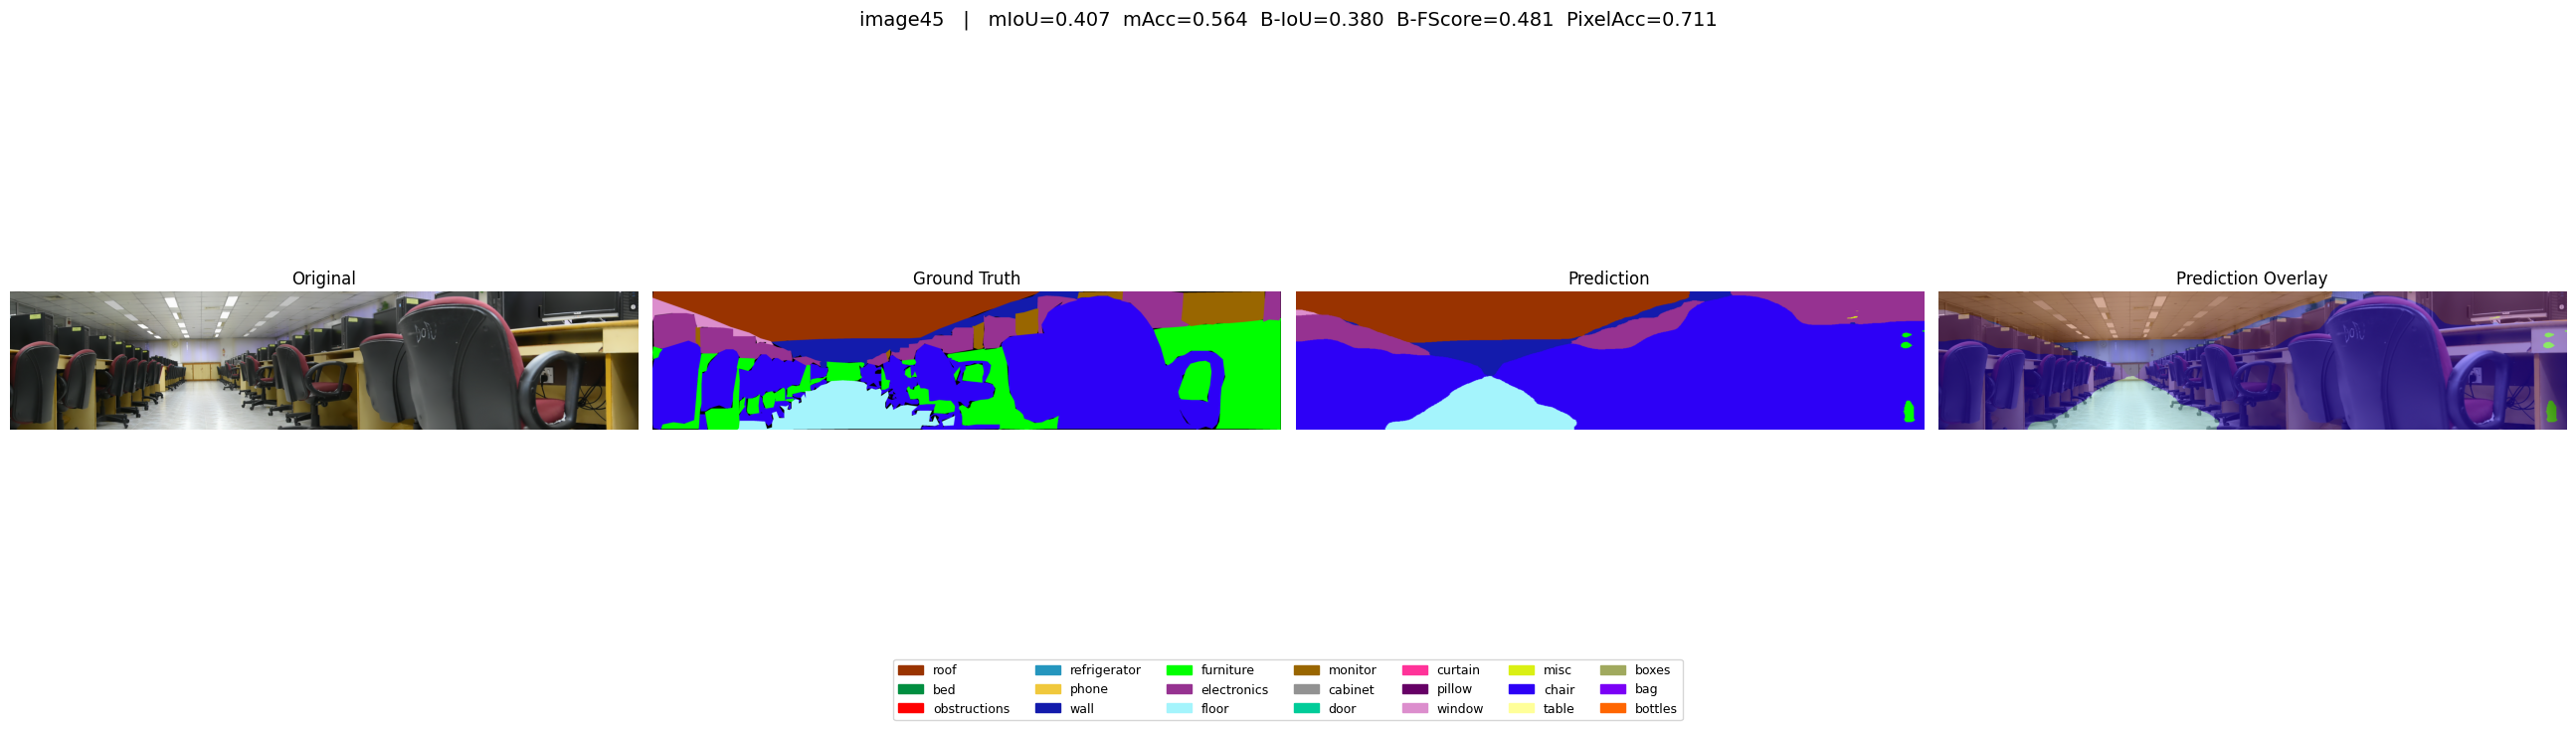

image45               mIoU=0.4068  mAcc=0.5639  B-IoU=0.3797  B-FScore=0.4809  PixelAcc=0.7114

Processed 1 val images.
Raw index masks saved to:      C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\val_inference_boundary\predicted_masks
Colorized prediction masks:    C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\val_inference_boundary\predicted_masks_color
Colorized GT masks:            C:\Users\Nighil Natarajan\Desktop\segformer_code_files\segformer_losses\Trained_model_vplab\val_inference_boundary\gt_masks_color


In [ ]:
# ============== 5. RUN INFERENCE OVER THE WHOLE VAL FOLDER ==============
# Set SHOW_EVERY_IMAGE = False if you have a lot of val images and only want the
# final averaged numbers + saved PNGs, without a matplotlib figure per image.
SHOW_EVERY_IMAGE = True

# Also save colorized GT masks (in addition to colorized predictions)? Set False to skip.
SAVE_GT_COLOR = True

PRED_DIR = OUTPUT_DIR / "predicted_masks"
PRED_DIR.mkdir(parents=True, exist_ok=True)

COLOR_PRED_DIR = OUTPUT_DIR / "predicted_masks_color"
COLOR_PRED_DIR.mkdir(parents=True, exist_ok=True)

if SAVE_GT_COLOR:
    COLOR_GT_DIR = OUTPUT_DIR / "gt_masks_color"
    COLOR_GT_DIR.mkdir(parents=True, exist_ok=True)

per_image_rows = []          # one row per image: mIoU, mAcc, Boundary IoU, Boundary F-score, mDice, pixel acc
running_intersection   = np.zeros(NUM_CLASSES)   # for dataset-level aggregated mIoU
running_union          = np.zeros(NUM_CLASSES)
running_gt_pixels      = np.zeros(NUM_CLASSES)   # for dataset-level aggregated mAcc (class-wise TP / GT)
running_b_intersection = np.zeros(NUM_CLASSES)   # for dataset-level aggregated Boundary IoU
running_b_union        = np.zeros(NUM_CLASSES)
running_correct = 0
running_total   = 0

for stem in stems:
    img_path, gt_path = img_lookup[stem], mask_lookup[stem]

    image_bgr = cv2.imread(str(img_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    gt_mask = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)
    if gt_mask.shape[:2] != image_rgb.shape[:2]:
        gt_mask = cv2.resize(gt_mask, (image_rgb.shape[1], image_rgb.shape[0]),
                              interpolation=cv2.INTER_NEAREST)

    pred_mask = predict_mask(image_rgb)

    # ---- save raw predicted index mask (for reuse / audit) ----
    cv2.imwrite(str(PRED_DIR / f"{stem}.png"), pred_mask)

    # ---- colorize prediction (and optionally GT) using the VP Lab palette, then save ----
    pred_color = colorize(pred_mask, palette_np)   # HxWx3 RGB, uint8
    cv2.imwrite(str(COLOR_PRED_DIR / f"{stem}.png"), cv2.cvtColor(pred_color, cv2.COLOR_RGB2BGR))

    if SAVE_GT_COLOR:
        gt_color_save = colorize(gt_mask, palette_np)
        cv2.imwrite(str(COLOR_GT_DIR / f"{stem}.png"), cv2.cvtColor(gt_color_save, cv2.COLOR_RGB2BGR))

    # ---- metrics for this image ----
    (
        ious, dices, accs,
        b_ious, bf_scores,
        b_inters, b_unis,
        n_valid, n_correct
    ) = compute_all_metrics_per_class(pred_mask, gt_mask, NUM_CLASSES)

    valid_ious      = ious[~np.isnan(ious)]
    valid_dices     = dices[~np.isnan(dices)]
    valid_accs      = accs[~np.isnan(accs)]
    valid_b_ious    = b_ious[~np.isnan(b_ious)]
    valid_bf_scores = bf_scores[~np.isnan(bf_scores)]

    img_miou    = valid_ious.mean() if len(valid_ious) else np.nan
    img_macc    = valid_accs.mean() if len(valid_accs) else np.nan
    img_biou    = valid_b_ious.mean() if len(valid_b_ious) else np.nan
    img_bfscore = valid_bf_scores.mean() if len(valid_bf_scores) else np.nan
    img_mdice   = valid_dices.mean() if len(valid_dices) else np.nan
    img_pacc    = n_correct / n_valid if n_valid else np.nan

    per_image_rows.append({
        "image": stem,
        "mIoU": img_miou,
        "mAcc": img_macc,
        "Boundary_IoU": img_biou,
        "Boundary_FScore": img_bfscore,
        "mDice": img_mdice,
        "pixel_acc": img_pacc
    })

    # ---- accumulate for dataset-level aggregated metrics ----
    valid_px = gt_mask != IGNORE_INDEX
    for c in range(NUM_CLASSES):
        p = (pred_mask == c) & valid_px
        g = (gt_mask == c) & valid_px
        running_intersection[c] += np.logical_and(p, g).sum()
        running_union[c]        += np.logical_or(p, g).sum()
        running_gt_pixels[c]    += g.sum()

    running_b_intersection += b_inters
    running_b_union        += b_unis
    running_correct += n_correct
    running_total   += n_valid

    # ---- visualize (reuse the already-computed pred_color; still need gt_color for display) ----
    if SHOW_EVERY_IMAGE:
        gt_color   = gt_color_save if SAVE_GT_COLOR else colorize(gt_mask, palette_np)
        blended    = cv2.addWeighted(image_rgb, 0.6, pred_color, 0.4, 0.0)

        fig, ax = plt.subplots(1, 4, figsize=(26, 7))
        ax[0].imshow(image_rgb);  ax[0].set_title("Original");           ax[0].axis("off")
        ax[1].imshow(gt_color);   ax[1].set_title("Ground Truth");       ax[1].axis("off")
        ax[2].imshow(pred_color); ax[2].set_title("Prediction");         ax[2].axis("off")
        ax[3].imshow(blended);    ax[3].set_title("Prediction Overlay"); ax[3].axis("off")

        fig.suptitle(
            f"{stem}   |   mIoU={img_miou:.3f}  mAcc={img_macc:.3f}  "
            f"B-IoU={img_biou:.3f}  B-FScore={img_bfscore:.3f}  PixelAcc={img_pacc:.3f}",
            fontsize=14
        )
        fig.legend(handles=legend_patches, loc="lower center", ncol=7, fontsize=9,
                   bbox_to_anchor=(0.5, -0.05))
        plt.tight_layout(rect=[0, 0.05, 1, 0.95])
        plt.show()

    print(
        f"{stem:20s}  mIoU={img_miou:.4f}  mAcc={img_macc:.4f}  "
        f"B-IoU={img_biou:.4f}  B-FScore={img_bfscore:.4f}  PixelAcc={img_pacc:.4f}"
    )

print(f"\nProcessed {len(stems)} val images.")
print(f"Raw index masks saved to:      {PRED_DIR}")
print(f"Colorized prediction masks:    {COLOR_PRED_DIR}")
if SAVE_GT_COLOR:
    print(f"Colorized GT masks:            {COLOR_GT_DIR}")

In [ ]:
# ============== 6. AVERAGE RESULTS OVER THE WHOLE VAL FOLDER ==============

per_image_df = pd.DataFrame(per_image_rows)
per_image_df.to_csv(OUTPUT_DIR / "per_image_metrics.csv", index=False)

num_val_images = len(per_image_df)  # <-- count of images actually averaged over

# --- (A) simple average of each image's own scores ---
avg_of_image_miou     = per_image_df["mIoU"].mean()
avg_of_image_macc     = per_image_df["mAcc"].mean()
avg_of_image_biou     = per_image_df["Boundary_IoU"].mean()
avg_of_image_bfscore  = per_image_df["Boundary_FScore"].mean()
avg_of_image_mdice    = per_image_df["mDice"].mean()
avg_of_image_pacc     = per_image_df["pixel_acc"].mean()

# --- (B) dataset-level aggregated metrics: pool pixels/boundaries over ALL images first ---
with np.errstate(invalid="ignore"):
    class_iou_dataset   = np.where(running_union > 0, running_intersection / running_union, np.nan)
    class_acc_dataset   = np.where(running_gt_pixels > 0, running_intersection / running_gt_pixels, np.nan)
    class_biou_dataset  = np.where(running_b_union > 0, running_b_intersection / running_b_union, np.nan)

dataset_miou  = np.nanmean(class_iou_dataset)
dataset_macc  = np.nanmean(class_acc_dataset)
dataset_biou  = np.nanmean(class_biou_dataset)
dataset_pacc  = running_correct / running_total

print("=" * 65)
print("AVERAGE OVER VAL FOLDER  (mean of each image's own score)")
print("=" * 65)
print(f"Number of val images   : {num_val_images}")
print(f"Average mIoU          : {avg_of_image_miou:.4f}")
print(f"Average mAcc          : {avg_of_image_macc:.4f}")
print(f"Average Boundary IoU   : {avg_of_image_biou:.4f}")
print(f"Average Boundary F1    : {avg_of_image_bfscore:.4f}")
print(f"Average mDice         : {avg_of_image_mdice:.4f}")
print(f"Average Pixel Acc      : {avg_of_image_pacc:.4f}")

print("\n" + "=" * 65)
print("DATASET-LEVEL AGGREGATED (pool all pixels/boundaries first)")
print("=" * 65)
print(f"Number of val images   : {num_val_images}")
print(f"Aggregated mIoU        : {dataset_miou:.4f}")
print(f"Aggregated mAcc        : {dataset_macc:.4f}")
print(f"Aggregated Boundary IoU: {dataset_biou:.4f}")
print(f"Aggregated PixelAcc    : {dataset_pacc:.4f}")

print("\nPer-class aggregated metrics:")
per_class_df = pd.DataFrame({
    "Class": classes,
    "IoU": np.round(class_iou_dataset, 4),
    "Accuracy": np.round(class_acc_dataset, 4),
    "Boundary_IoU": np.round(class_biou_dataset, 4)
})
print(per_class_df.to_string(index=False))

per_class_df.to_csv(OUTPUT_DIR / "per_class_aggregated_metrics.csv", index=False)

# Also keep per_class_aggregated_iou.csv for backward compatibility
class_iou_df = pd.DataFrame({"Class": classes, "IoU": np.round(class_iou_dataset, 4)})
class_iou_df.to_csv(OUTPUT_DIR / "per_class_aggregated_iou.csv", index=False)

print(f"\nSaved: {OUTPUT_DIR / 'per_image_metrics.csv'}")
print(f"Saved: {OUTPUT_DIR / 'per_class_aggregated_metrics.csv'}")
print(f"Saved: {OUTPUT_DIR / 'per_class_aggregated_iou.csv'}")

AVERAGE OVER VAL FOLDER  (mean of each image's own score)
Number of val images   : 1
Average mIoU          : 0.4068
Average mAcc          : 0.5639
Average Boundary IoU   : 0.3797
Average Boundary F1    : 0.4809
Average mDice         : 0.4773
Average Pixel Acc      : 0.7114

DATASET-LEVEL AGGREGATED (pool all pixels/boundaries first)
Number of val images   : 1
Aggregated mIoU        : 0.4068
Aggregated mAcc        : 0.5639
Aggregated Boundary IoU: 0.3797
Aggregated PixelAcc    : 0.7114

Per-class aggregated metrics:
       Class    IoU  Accuracy  Boundary_IoU
        roof 0.8991    1.0000        0.8026
         bed    NaN       NaN           NaN
obstructions    NaN       NaN           NaN
refrigerator    NaN       NaN           NaN
       phone    NaN       NaN           NaN
        wall 0.6335    0.7571        0.6335
   furniture 0.0161    0.0161        0.0070
 electronics 0.4958    0.7226        0.4887
       floor 0.8916    0.9378        0.8704
     monitor 0.0000    0.0000        0.